# Hilbert Sorting, `SnapIndex`, and `GeoKDTree`

`scgraph` supports two spatial indexes with the same query API:
- **`SnapIndex`**: reads coordinates in place; expects spatially ordered nodes (for example, via a Hilbert curve).
- **`GeoKDTree`** (`geokdtree`): 3D spherical KD-tree; builds its own tree from points in any order.


In [1]:
# Optional for plotting: !pip install matplotlib
import math
import random
import time

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from geokdtree import GeoKDTree

from scgraph import GeoGraph
from scgraph.helpers.hilbert import hilbert_order
from scgraph.utils import haversine, has_cpp

try:
    from scgraph.cpp import NodeOrderError, SnapIndex
except ImportError:
    from scgraph.helpers.snap_index import NodeOrderError, SnapIndex

print(f"C++ backend: {has_cpp()}")


C++ backend: True


## 1. Hilbert Curve Over 1,000 Points

`hilbert_order(points)` orders `(latitude, longitude)` pairs along a 2D space-filling curve so nearby coordinates stay close in memory.


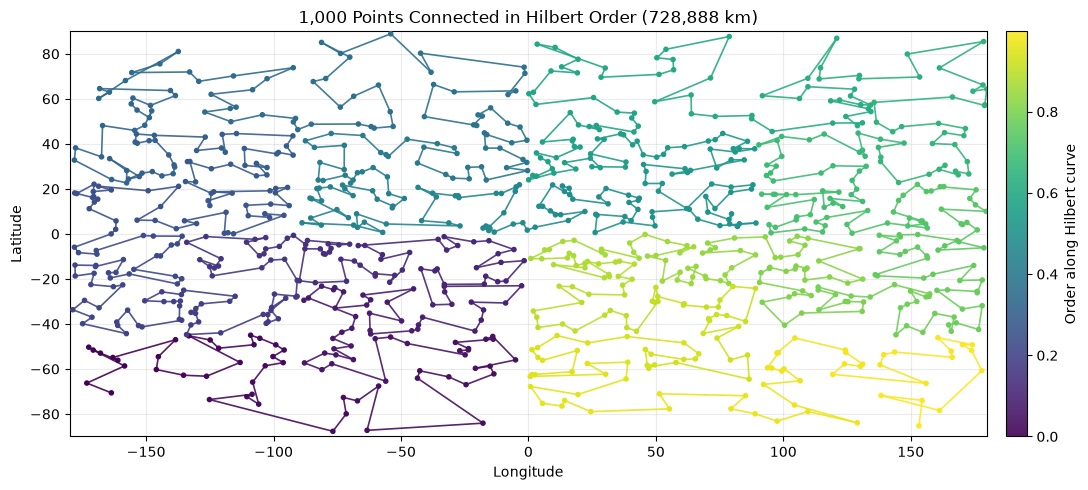

In [2]:
rng = random.Random(42)
points = [
    [math.degrees(math.asin(2 * rng.random() - 1)), rng.uniform(-180, 180)]
    for _ in range(1000)
]

order = hilbert_order(points)
ordered_points = [points[i] for i in order]
hilbert_km = sum(haversine(a, b) for a, b in zip(ordered_points, ordered_points[1:]))

# Split segments crossing ±180° longitude so they do not span the flat plot
segments, seg_pos = [], []
for i, (a, b) in enumerate(zip(ordered_points, ordered_points[1:])):
    if abs(b[1] - a[1]) <= 180:
        segments.append([(a[1], a[0]), (b[1], b[0])])
        seg_pos.append(i / len(ordered_points))

fig, ax = plt.subplots(figsize=(11, 5))
lc = LineCollection(segments, cmap="viridis", linewidths=1.2, alpha=0.9)
lc.set_array(seg_pos)
ax.add_collection(lc)
ax.scatter(
    [p[1] for p in ordered_points],
    [p[0] for p in ordered_points],
    c=range(len(ordered_points)),
    cmap="viridis",
    s=9,
    zorder=3,
)
fig.colorbar(lc, ax=ax, label="Order along Hilbert curve", fraction=0.025, pad=0.02)
ax.set_title(f"1,000 Points Connected in Hilbert Order ({hilbert_km:,.0f} km)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


## 2. Building `GeoKDTree` and `SnapIndex`

Both indexes project `(latitude, longitude)` onto the 3D unit sphere `(x, y, z)`, avoiding polar distortion and `±180°` wrapping issues of a naive 2D KD-tree.
`GeoKDTree` accepts points in any order, whereas `SnapIndex` raises `NodeOrderError` until points are spatially ordered.


In [3]:
kdtree_raw = GeoKDTree(points)

try:
    SnapIndex(points)
except NodeOrderError as err:
    print("Unordered SnapIndex -> NodeOrderError:")
    print(" ", str(err).split(".")[0])

snap = SnapIndex(ordered_points)
kdtree = GeoKDTree(ordered_points)
print("Ordered SnapIndex & GeoKDTree -> OK")


Unordered SnapIndex -> NodeOrderError:
  nodes scattered in the order given: a query would scan about 29 groups of 32 nodes (at most 16)
Ordered SnapIndex & GeoKDTree -> OK


## 3. Equivalence

Both indexes implement `closest_idx(point)` and `closest_idx_per_quadrant(point)` and return the exact same nodes across the globe (using `order[idx]` to map back to original indices).


In [4]:
queries = [
    [math.degrees(math.asin(2 * rng.random() - 1)), rng.uniform(-180, 180)]
    for _ in range(500)
] + [[90.0, 0.0], [-90.0, 0.0], [0.0, 180.0], [0.0, -180.0], [48.85, 2.35]]

closest_matches = sum(
    order[snap.closest_idx(q)] == kdtree_raw.closest_idx(q) for q in queries
)
quad_matches = sum(
    {d: (order[i] if i is not None else None) for d, i in snap.closest_idx_per_quadrant(q).items()}
    == kdtree_raw.closest_idx_per_quadrant(q)
    for q in queries
)
print(f"closest_idx matches             : {closest_matches}/{len(queries)}")
print(f"closest_idx_per_quadrant matches: {quad_matches}/{len(queries)}")

# Example right across the ±180° antimeridian (SE wraps to -178.1°)
q_antimeridian = [0.0, 179.5]
print("Antimeridian [0.0, 179.5]:")
print("  SnapIndex:", snap.closest_idx_per_quadrant(q_antimeridian))
print("  GeoKDTree:", kdtree.closest_idx_per_quadrant(q_antimeridian))


closest_idx matches             : 505/505
closest_idx_per_quadrant matches: 505/505
Antimeridian [0.0, 179.5]:
  SnapIndex: {'ne': 739, 'nw': 744, 'se': 235, 'sw': 746}
  GeoKDTree: {'ne': 739, 'nw': 744, 'se': 235, 'sw': 746}


Inside `GeoGraph`, `geo.snap_index` defaults to `SnapIndex` and can be swapped to `geo.geokdtree` with identical shortest paths:


In [5]:
ring = [{} for _ in ordered_points]
for i in range(len(ordered_points)):
    j = (i + 1) % len(ordered_points)
    ring[i][j] = ring[j][i] = haversine(ordered_points[i], ordered_points[j])

geo = GeoGraph(graph=ring, nodes=ordered_points)
res_snap = geo.get_shortest_path({"latitude": 48.85, "longitude": 2.35}, {"latitude": 40.71, "longitude": -74.01})

geo.snap_index = geo.geokdtree
res_kd = geo.get_shortest_path({"latitude": 48.85, "longitude": 2.35}, {"latitude": 40.71, "longitude": -74.01})

assert res_snap == res_kd
print(f"Shortest path parity: {res_snap['length']:,.2f} km (exact match: {res_snap['coordinate_path'] == res_kd['coordinate_path']})")


Shortest path parity: 22,280.66 km (exact match: True)


## 4. High Latitudes and Antimeridian Performance

In `closest_idx_per_quadrant` (used by `GeoGraph.get_shortest_path`), empty quadrants and `±180°` boundaries separate the two indexes:
- **`GeoKDTree`** only splits `(x, y, z)` planes, which do not represent East/West longitude bounds cleanly, so it traverses many subtrees when a quadrant is empty or crosses `±180°`.
- **`SnapIndex`** stores explicit `±180°`-aware `(min_lat, max_lat, min_lon, max_lon)` bounds per group and skips empty or wrapped quadrants immediately.

Below is a simple 100,000-point dataset covering continental latitudes (`[-55°, 72°]`, longitudes `[-130°, 145°]` excluding the mid-Atlantic):


In [6]:
rng_b = random.Random(42)
land_points = []
while len(land_points) < 100_000:
    lat = rng_b.uniform(-55, 72)
    lon = rng_b.uniform(-130, 145)
    if -35 < lon < -15:
        continue
    land_points.append([lat, lon])

land_ordered = [land_points[i] for i in hilbert_order(land_points)]

t0 = time.perf_counter()
snap_100k = SnapIndex(land_ordered)
snap_build_ms = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
kd_100k = GeoKDTree(land_ordered)
kd_build_ms = (time.perf_counter() - t0) * 1000
print(f"Build (100k): SnapIndex {snap_build_ms:.1f} ms | GeoKDTree {kd_build_ms:.1f} ms ({kd_build_ms / snap_build_ms:.1f}x slower)")


def avg_us(index, qs, method, repeat=5):
    fn = getattr(index, method)
    for q in qs[:10]:
        fn(q)
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter()
        for q in qs:
            fn(q)
        best = min(best, (time.perf_counter() - t0) * 1e6 / len(qs))
    return best


zones = {
    "Europe\n(45–52°N)": [[rng_b.uniform(45, 52), rng_b.uniform(0, 10)] for _ in range(200)],
    "Arctic\n(78–88°N)": [[rng_b.uniform(78, 88), rng_b.uniform(-180, 180)] for _ in range(200)],
    "Antarctic\n(78–88°S)": [[rng_b.uniform(-88, -78), rng_b.uniform(-180, 180)] for _ in range(200)],
    "Antimeridian\n(±175–180°)": [[rng_b.uniform(-20, 20), rng_b.choice([-1, 1]) * rng_b.uniform(175, 180)] for _ in range(200)],
}

results = []
for name, qs in zones.items():
    sc, kc = avg_us(snap_100k, qs, "closest_idx"), avg_us(kd_100k, qs, "closest_idx")
    sq, kq = avg_us(snap_100k, qs, "closest_idx_per_quadrant"), avg_us(kd_100k, qs, "closest_idx_per_quadrant")
    results.append((name, sq, kq))
    print(f"{name.replace(chr(10), ' '):26s} | closest: {sc:4.1f} vs {kc:4.1f} us | quadrant: Snap {sq:5.1f} us, KD {kq:6.1f} us ({kq / sq:4.1f}x)")


Build (100k): SnapIndex 20.0 ms | GeoKDTree 82.9 ms (4.1x slower)
Europe (45–52°N)           | closest:  1.2 vs  0.4 us | quadrant: Snap   6.6 us, KD    1.8 us ( 0.3x)
Arctic (78–88°N)           | closest:  1.9 vs  3.2 us | quadrant: Snap   6.3 us, KD   20.5 us ( 3.2x)
Antarctic (78–88°S)        | closest:  2.6 vs  2.3 us | quadrant: Snap   7.5 us, KD  100.3 us (13.3x)


Antimeridian (±175–180°)   | closest:  1.6 vs  1.7 us | quadrant: Snap  11.3 us, KD  152.1 us (13.5x)


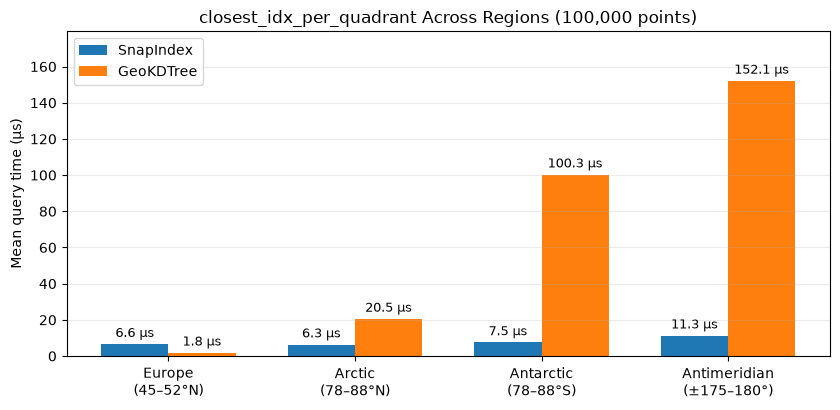

In [7]:
labels = [r[0] for r in results]
snap_us = [r[1] for r in results]
kd_us = [r[2] for r in results]
x = range(len(labels))
w = 0.36

fig, ax = plt.subplots(figsize=(8.5, 4.2))
b1 = ax.bar([i - w / 2 for i in x], snap_us, w, label="SnapIndex", color="#1f77b4")
b2 = ax.bar([i + w / 2 for i in x], kd_us, w, label="GeoKDTree", color="#ff7f0e")
ax.bar_label(b1, fmt="%.1f µs", padding=3, fontsize=9)
ax.bar_label(b2, fmt="%.1f µs", padding=3, fontsize=9)

ax.set_xticks(list(x))
ax.set_xticklabels(labels)
ax.set_ylabel("Mean query time (µs)")
ax.set_title("closest_idx_per_quadrant Across Regions (100,000 points)")
ax.set_ylim(0, max(kd_us) * 1.18)
ax.legend()
ax.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### Summary

- **Mid-latitudes**: both indexes answer in microseconds (`GeoKDTree` is slightly faster when all 4 quadrants have nearby nodes).
- **High latitudes & antimeridian**: `SnapIndex` stays fast via explicit lat/lon box pruning, whereas `GeoKDTree` slows down sharply when quadrants are empty or cross `±180°`.
- **Build**: `SnapIndex` builds faster directly on Hilbert-ordered coordinates.
